# 04: Hour-by-hour simulation: how much of the cooking load does the field meet?

*Phase 2.4 of the extension. The reasoning and the findings are explained in `docs/report.md`, section 2.4.*

The final report sizes 14 dishes on a *daily* total and states that the system has no storage, so it cannot say how much of the load is met when. This notebook runs the field through the 8760 hours of the IIT Bombay typical year with a meal schedule, an optional steam store and LPG backup, and answers three questions:

1. How much of the steam demand does the final report design (14 dishes, no storage) actually meet?
2. What does a store of a given size add?
3. Do the LPG savings the final report claims (975 cylinders a year) hold up?

Assumptions that the final report does not state (meal hours, store efficiencies) are in `configs/base.yaml` under `schedule`, `storage` and `backup`, and are varied in notebook 05. Results here are *conditional on them*.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from en630.config import load_config
from en630.plotting import INK, SERIES, SURFACE, apply_theme, save
from en630.simulate import collector_heat_mj, daily_energy, simulate
from en630.weather import IIT_BOMBAY, clean_dni, read_tmy_csv, to_local

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*dayofyear.*")
apply_theme()
DATA, FIG = Path("../data"), Path("../docs/figures")
FIG.mkdir(parents=True, exist_ok=True)

cfg = load_config()
wx = read_tmy_csv(DATA / "pvgis_tmy_iitb.csv")
wx["dni"] = clean_dni(wx, IIT_BOMBAY, "centre")
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
N = 14  # dishes in the final report design

per_dish = collector_heat_mj(wx, IIT_BOMBAY, cfg)
base = simulate(wx, IIT_BOMBAY, cfg, N, 0.0)
print(f"One dish: {per_dish.sum() / 3600:.1f} MWh of useful heat a year ({per_dish.sum():,.0f} MJ); 14 dishes: {base.annual['useful_collector_mwh']:.0f} MWh.")
print(f"Daily steam demand: {base.annual['demand_mj'] / 365:,.1f} MJ (the final report: 1435.89 MJ).")

One dish: 12.3 MWh of useful heat a year (44,405 MJ); 14 dishes: 173 MWh.
Daily steam demand: 1,435.9 MJ (the final report: 1435.89 MJ).


## 1: The mismatch between sun and kitchen

Mean hourly profile of collected heat (14 dishes) against the steam the kitchen draws, in a clear month (May) and a monsoon month (July).

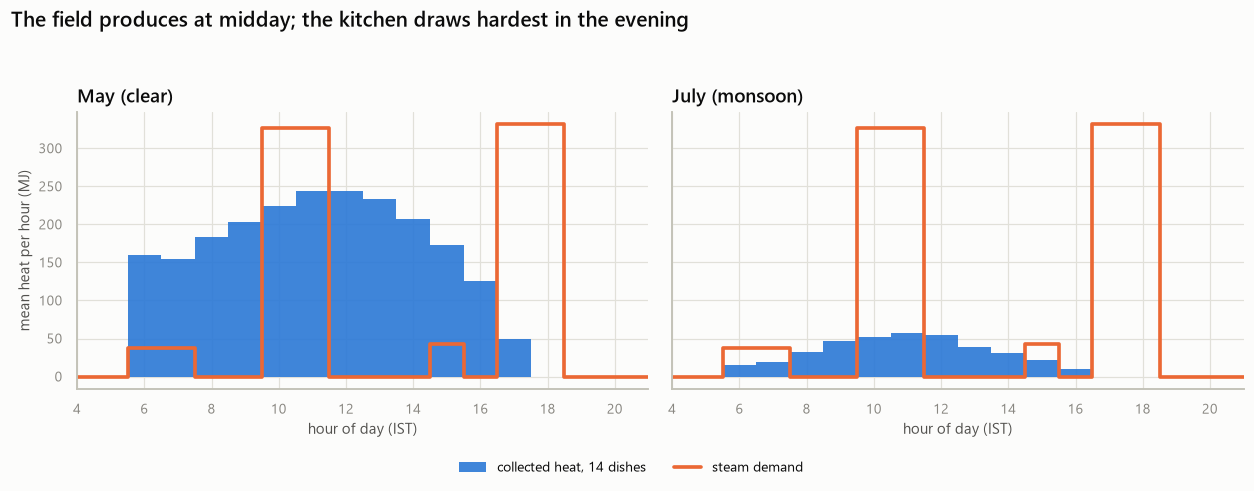

Share of the day's steam demand drawn after 17:00: 46%


In [2]:
loc = to_local(base.hourly, IIT_BOMBAY)
loc["hour"] = (loc.index - pd.Timedelta(minutes=30)).hour   # centre-of-hour stamps -> clock hour that starts the interval
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9), sharey=True)
for ax, month, name in zip(axes, (5, 7), ("May (clear)", "July (monsoon)")):
    m = loc[loc.month == month].groupby("hour")[["collected_mj", "demand_mj"]].mean().reindex(range(24), fill_value=0)
    ax.fill_between(m.index, m.collected_mj, step="mid", color=SERIES[0], alpha=0.9, linewidth=0, label="collected heat, 14 dishes")
    ax.step(m.index, m.demand_mj, where="mid", color=SERIES[1], linewidth=2.4, label="steam demand")
    ax.set_title(name)
    ax.set_xlabel("hour of day (IST)")
    ax.set_xlim(4, 21)
    ax.set_xticks(range(4, 22, 2))
axes[0].set_ylabel("mean heat per hour (MJ)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.07))
fig.suptitle("The field produces at midday; the kitchen draws hardest in the evening", x=0.01, y=1.04, ha="left", fontsize=13.5, fontweight="semibold")
fig.tight_layout()
save(fig, FIG / "sim_profiles.png")
plt.show()
print("Share of the day's steam demand drawn after 17:00:", f"{loc.loc[loc.hour >= 17, 'demand_mj'].sum() / loc['demand_mj'].sum():.0%}")

## 2: What a store adds

Solar fraction (share of the annual steam demand met by solar, directly or through the store) for the 14-dish field and storage sizes from none to about three days of demand.

,solar fraction,curtailed (MWh),cylinders displaced / yr,CO2 avoided (t/yr)
store (MJ),,,,
0,0.341,123.114,454.359,19.356
250,0.549,88.518,732.781,31.216
500,0.674,67.599,898.808,38.289
750,0.770,51.072,1027.180,43.758
1000,0.775,48.137,1034.397,44.065
1500,0.778,43.585,1038.301,44.232
2000,0.779,39.432,1039.610,44.287
3000,0.780,31.427,1041.254,44.357
4000,0.781,23.909,1042.058,44.392


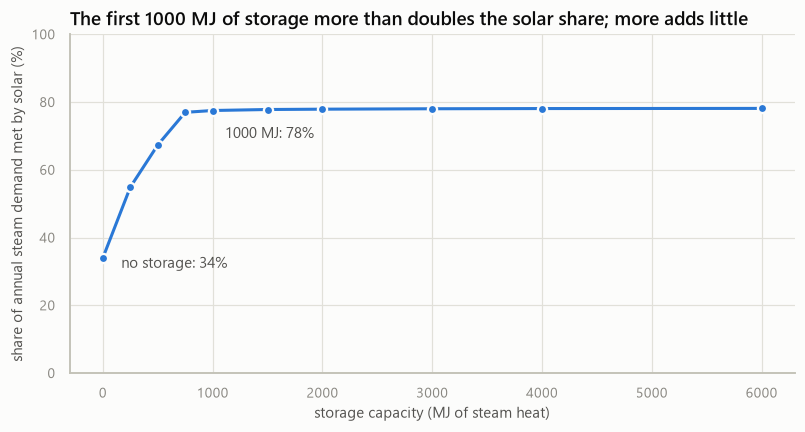

In [3]:
sizes = [0, 250, 500, 750, 1000, 1500, 2000, 3000, 4000, 6000]
rows = []
for c in sizes:
    a = simulate(wx, IIT_BOMBAY, cfg, N, c).annual
    rows.append({"store (MJ)": c, "solar fraction": a["solar_fraction"], "curtailed (MWh)": a["curtailed_mj"] / 3600,
                 "cylinders displaced / yr": a["cylinders_displaced"], "CO2 avoided (t/yr)": a["co2_avoided_t"]})
sweep = pd.DataFrame(rows).set_index("store (MJ)")
display(sweep.round(3))

fig, ax = plt.subplots(figsize=(8.5, 4.0))
ax.plot(sweep.index, sweep["solar fraction"] * 100, color=SERIES[0], marker="o", markersize=6, markeredgecolor=SURFACE, markeredgewidth=1.5)
ax.set_xlabel("storage capacity (MJ of steam heat)")
ax.set_ylabel("share of annual steam demand met by solar (%)")
ax.set_ylim(0, 100)
ax.annotate(f"no storage: {sweep['solar fraction'].iloc[0]:.0%}", (0, sweep['solar fraction'].iloc[0] * 100), xytext=(12, -4), textcoords="offset points", fontsize=9.5, color=INK["secondary"], va="center")
i = sizes.index(1000)
ax.annotate(f"1000 MJ: {sweep['solar fraction'].iloc[i]:.0%}", (1000, sweep['solar fraction'].iloc[i] * 100), xytext=(8, -18), textcoords="offset points", fontsize=9.5, color=INK["secondary"])
ax.set_title("The first 1000 MJ of storage more than doubles the solar share; more adds little")
save(fig, FIG / "sim_storage_sweep.png")
plt.show()

## 3: Where the monsoon bites

Monthly solar heat delivered to the kitchen (14 dishes) with no store and with 1000 MJ, as a share of that month's demand.

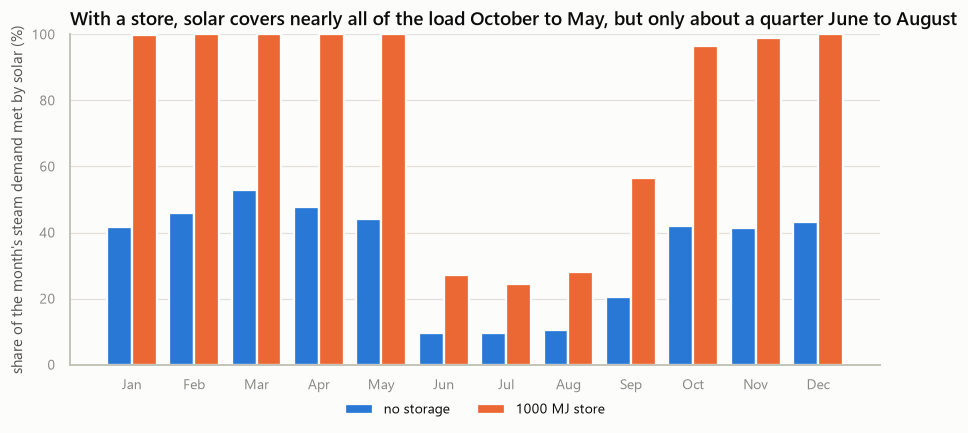

with a 1000 MJ store, monsoon months (Jun-Sep): {6: 0.27, 7: 0.25, 8: 0.28, 9: 0.57}
days on which the collected heat alone would cover the whole day's demand (14 dishes): 67%


In [4]:
def monthly_fraction(res):
    h = to_local(res.hourly, IIT_BOMBAY)
    g = h.groupby("month")
    return (g.direct_mj.sum() + g.from_store_mj.sum()) / g.demand_mj.sum()

no_store = monthly_fraction(base)
with_store = monthly_fraction(simulate(wx, IIT_BOMBAY, cfg, N, 1000.0))
x = np.arange(12)
fig, ax = plt.subplots(figsize=(9.5, 3.9))
ax.bar(x - 0.2, no_store.to_numpy() * 100, 0.4, color=SERIES[0], edgecolor=SURFACE, linewidth=1.5, label="no storage")
ax.bar(x + 0.2, with_store.to_numpy() * 100, 0.4, color=SERIES[1], edgecolor=SURFACE, linewidth=1.5, label="1000 MJ store")
ax.set_xticks(x, MONTHS)
ax.set_ylabel("share of the month's steam demand met by solar (%)")
ax.set_ylim(0, 100)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, -0.08))
ax.set_title("With a store, solar covers nearly all of the load October to May, but only about a quarter June to August")
save(fig, FIG / "sim_monthly_fraction.png")
plt.show()
print("with a 1000 MJ store, monsoon months (Jun-Sep):", with_store.loc[6:9].round(2).to_dict())
de = daily_energy(base, IIT_BOMBAY)
print(f"days on which the collected heat alone would cover the whole day's demand (14 dishes): {(de.collected_mj >= de.demand_mj).mean():.0%}")

## 4: Do the LPG savings the final report claims hold up?

The final report uses two incompatible bases for the cylinders saved: 3.67 a day (about 1340 a year) in the sustainability section, and 975 a year in the CO₂ and fuel-saving lines. The simulation gives a third figure, using the final report's own conversion (displaced steam heat over 654.6 MJ per cylinder and the 0.6 stove efficiency).

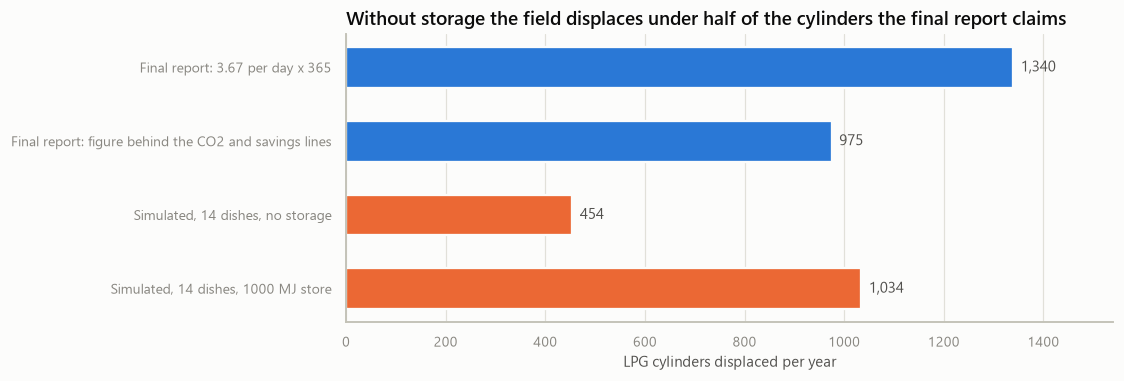

Useful annual heat, 14 dishes with 11.65 m2 aperture: 173 MWh; scaled to the performance report's 16 m2: 237 MWh (the performance report gives 194.6 MWh).


In [5]:
cases = {
    "Final report: 3.67 per day x 365": 3.67 * 365,
    "Final report: figure behind the CO2 and savings lines": 975,
    "Simulated, 14 dishes, no storage": base.annual["cylinders_displaced"],
    "Simulated, 14 dishes, 1000 MJ store": simulate(wx, IIT_BOMBAY, cfg, N, 1000.0).annual["cylinders_displaced"],
}
fig, ax = plt.subplots(figsize=(9, 3.4))
names, vals = list(cases), list(cases.values())
colors = [SERIES[0], SERIES[0], SERIES[1], SERIES[1]]
ax.barh(names[::-1], vals[::-1], color=colors[::-1], height=0.55, edgecolor=SURFACE, linewidth=1.5)
for i, v in enumerate(vals[::-1]):
    ax.text(v + 15, i, f"{v:,.0f}", va="center", fontsize=9.5, color=INK["secondary"])
ax.set_xlim(0, max(vals) * 1.15)
ax.set_xlabel("LPG cylinders displaced per year")
ax.grid(axis="y", visible=False)
ax.set_title("Without storage the field displaces under half of the cylinders the final report claims")
save(fig, FIG / "sim_cylinders.png")
plt.show()

useful = base.annual["useful_collector_mwh"]
print(f"Useful annual heat, 14 dishes with 11.65 m2 aperture: {useful:.0f} MWh; scaled to the performance report's 16 m2: {useful * 16 / 11.65:.0f} MWh (the performance report gives 194.6 MWh).")

## 5: How much does the answer depend on the meal hours?

The final report does not say when the meals are cooked. The schedule above puts a lot of steam demand in the evening. As a deliberately favourable bound, spread the same daily energy over daylight hours (10:00 to 15:00) and rerun without storage.

In [6]:
daylight = {**cfg, "schedule": {"morning": [10], "lunch": [11, 12], "snacks": [13], "dinner": [14, 15]}}
rows = {
    "assumed schedule (evening dinner), no store": simulate(wx, IIT_BOMBAY, cfg, N, 0.0).annual["solar_fraction"],
    "all cooking between 10:00 and 15:00, no store": simulate(wx, IIT_BOMBAY, daylight, N, 0.0).annual["solar_fraction"],
    "assumed schedule, 1000 MJ store": simulate(wx, IIT_BOMBAY, cfg, N, 1000.0).annual["solar_fraction"],
}
pd.Series(rows, name="solar fraction").map("{:.1%}".format).to_frame()

,solar fraction
"assumed schedule (evening dinner), no store",34.1%
"all cooking between 10:00 and 15:00, no store",55.6%
"assumed schedule, 1000 MJ store",77.5%


## What this notebook establishes, and what it does not

* **Established (given the assumed meal hours):** the final report design, 14 dishes with no storage, meets about a third of the annual steam demand, because the collectors produce at midday and the heaviest draws are in the evening. Cylinders displaced are about 450 a year, under half of the final report's 975 and a third of its 1340.
* **Established:** a store of about 1000 MJ raises the solar fraction to about three quarters and the displaced cylinders to about 1030, i.e. it would be needed to make the final report's savings claim true. Beyond that, more storage adds little: with the store, solar meets 96 to 100 % of the load from October to May but only 25 to 28 % in June to August (57 % in September), so the limit is the monsoon, when too little beam irradiance arrives to fill any store.
* **Established:** the collector model gives about 173 MWh a year for the 14 dishes (11.65 m² aperture each). The performance report reports 194.6 MWh using a 16 m² area, 1.65 MWh/m² of DNI and different efficiencies; the figures are not on the same basis.
* **Caveat on the early-morning heat:** the collected-heat profile starts at 06:00 with a substantial output, which depends on PVGIS beam values at low sun (see the 66 hours the artefact bound does not catch in notebook 03); the morning meal's solar share is therefore the least certain part.
* **Not established:** the meal hours (the bounding case in section 5 shows how much they matter), the store's efficiencies and losses, and the real PVGIS DNI in the monsoon. Notebook 05 propagates uncertainty in these and in the economics.